In [2]:
import os, pandas as pd
ROOT = "/kaggle/input/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign"
print(os.listdir(ROOT))
counts = {c: len(os.listdir(f"{ROOT}/Train/{c}")) for c in sorted(os.listdir(f"{ROOT}/Train"), key=int)}
s = pd.Series(counts)
print(len(s), "classes |", s.sum(), "images")
print(s.describe())
print(s.sort_values().head(5)); print(s.sort_values().tail(5))

['Meta', 'meta', 'Meta.csv', 'Train.csv', 'Test.csv', 'Test', 'test', 'Train', 'train']
43 classes | 39209 images
count      43.000000
mean      911.837209
std       695.856715
min       210.000000
25%       345.000000
50%       600.000000
75%      1425.000000
max      2250.000000
dtype: float64
0     210
19    210
37    210
27    240
41    240
dtype: int64
38    2070
12    2100
13    2160
1     2220
2     2250
dtype: int64


31590 7619 | shared signs: 0
min val images per class: 330


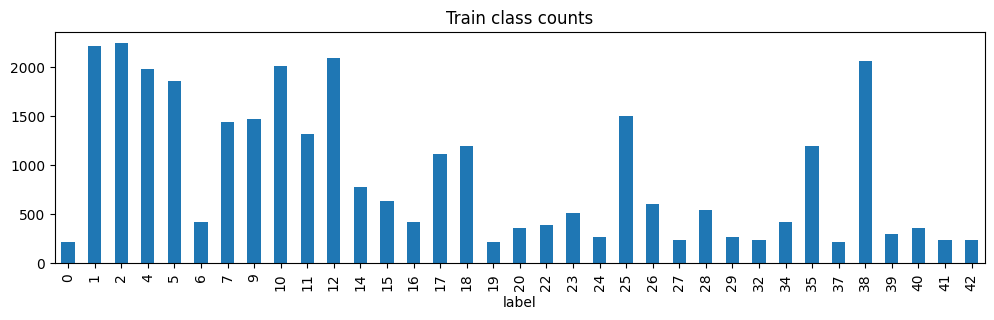

In [3]:
import os, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold

ROOT = "/kaggle/input/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign"
rows = []
for c in sorted(os.listdir(f"{ROOT}/Train"), key=int):
    for f in os.listdir(f"{ROOT}/Train/{c}"):
        if f.endswith(".png"):
            rows.append((f"{ROOT}/Train/{c}/{f}", int(c), f"{c}_{f.split('_')[0]}"))
df = pd.DataFrame(rows, columns=["path", "label", "track"])

# 80/20 split, stratified by class, grouped by physical sign (no leakage)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
tr_idx, va_idx = next(sgkf.split(df, df.label, groups=df.track))
train_df, val_df = df.iloc[tr_idx].reset_index(drop=True), df.iloc[va_idx].reset_index(drop=True)
print(len(train_df), len(val_df), "| shared signs:", len(set(train_df.track) & set(val_df.track)))
print("min val images per class:", val_df.label.value_counts().min())

train_df.label.value_counts().sort_index().plot(kind="bar", figsize=(12, 3), title="Train class counts")
plt.show()

In [4]:
import torch, torch.nn as nn, numpy as np
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
SIZE = 64   # GTSRB images are small; 64x64 trains fast and works well
# No horizontal flip: it would turn "turn left" into "turn right"
train_tf = transforms.Compose([transforms.Resize((SIZE, SIZE)), transforms.RandomRotation(10),
                               transforms.ColorJitter(0.3, 0.3, 0.3),
                               transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
val_tf = transforms.Compose([transforms.Resize((SIZE, SIZE)),
                             transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class GTSRB(Dataset):
    def __init__(self, df, tf): self.paths, self.labels, self.tf = df.path.values, df.label.values, tf
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        return self.tf(Image.open(self.paths[i]).convert("RGB")), int(self.labels[i])

train_dl = DataLoader(GTSRB(train_df, train_tf), batch_size=128, shuffle=True, num_workers=4)
val_dl = DataLoader(GTSRB(val_df, val_tf), batch_size=256, num_workers=4)

x, y = next(iter(train_dl))
print(x.shape, y[:10])

device: cuda
torch.Size([128, 3, 64, 64]) tensor([38,  2, 38,  9, 25,  5, 35, 40, 26,  5])


In [5]:
from torchvision import models
from sklearn.metrics import f1_score, classification_report
import json, copy

def make_model():
    m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    m.fc = nn.Linear(m.fc.in_features, 43)
    return m.to(device)

def evaluate(model):
    model.eval(); yt, yp = [], []
    with torch.no_grad():
        for x, y in val_dl:
            yp += model(x.to(device)).argmax(1).cpu().tolist(); yt += y.tolist()
    return yt, yp

def run(name, weighted, epochs=8, lr=1e-3):
    torch.manual_seed(42)
    model = make_model()
    counts = np.bincount(train_df.label, minlength=43)
    w = torch.tensor(counts.sum() / (43 * counts), dtype=torch.float32).to(device) if weighted else None
    loss_fn = nn.CrossEntropyLoss(weight=w)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    best, best_state = -1, None
    for ep in range(epochs):
        model.train()
        for x, y in train_dl:
            x, y = x.to(device), y.to(device)
            opt.zero_grad(); loss_fn(model(x), y).backward(); opt.step()
        sched.step()
        yt, yp = evaluate(model)
        f1 = f1_score(yt, yp, average="macro")
        print(f"{name} epoch {ep+1}/{epochs}  val macro-F1 {f1:.4f}")
        if f1 > best: best, best_state = f1, copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    yt, yp = evaluate(model)
    report = classification_report(yt, yp, output_dict=True, zero_division=0)
    torch.save({"state_dict": best_state, "size": SIZE}, f"{name}.pt")
    json.dump({"report": report, "class_counts": counts.tolist()}, open(f"{name}.metrics.json", "w"))
    return report

base_report = run("base", weighted=False)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 154MB/s]


base epoch 1/8  val macro-F1 0.0000
base epoch 2/8  val macro-F1 0.0000
base epoch 3/8  val macro-F1 0.0000
base epoch 4/8  val macro-F1 0.0000
base epoch 5/8  val macro-F1 0.0000
base epoch 6/8  val macro-F1 0.0000
base epoch 7/8  val macro-F1 0.0000
base epoch 8/8  val macro-F1 0.0000


In [6]:
model = make_model()
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()
model.train()
for i, (x, y) in enumerate(train_dl):
    x, y = x.to(device), y.to(device)
    opt.zero_grad(); out = model(x); loss = loss_fn(out, y); loss.backward(); opt.step()
    if i % 20 == 0: print(i, "loss", round(loss.item(), 4), "| NaN in output:", torch.isnan(out).any().item())
    if i == 100: break

yt, yp = evaluate(model)
print("val classes present:", len(set(yt)), "| predicted classes:", len(set(yp)),
      "| accuracy:", (np.array(yt) == np.array(yp)).mean())
print(pd.Series(yp).value_counts().head())

0 loss 4.2901 | NaN in output: False
20 loss 0.6604 | NaN in output: False
40 loss 0.3221 | NaN in output: False
60 loss 0.1341 | NaN in output: False
80 loss 0.1235 | NaN in output: False
100 loss 0.2508 | NaN in output: False
val classes present: 8 | predicted classes: 30 | accuracy: 0.0
12    1451
7     1414
5     1093
35     820
27     568
Name: count, dtype: int64


In [7]:
print("example file:", os.listdir(f"{ROOT}/Train/0")[0])

rows = []
for c in sorted(os.listdir(f"{ROOT}/Train"), key=int):
    for f in os.listdir(f"{ROOT}/Train/{c}"):
        if f.endswith(".png"):
            rows.append((f"{ROOT}/Train/{c}/{f}", int(c), f"{c}_{f.split('_')[1]}"))
df = pd.DataFrame(rows, columns=["path", "label", "track"])
print("distinct signs:", df.track.nunique())

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
tr_idx, va_idx = next(sgkf.split(df, df.label, groups=df.track))
train_df, val_df = df.iloc[tr_idx].reset_index(drop=True), df.iloc[va_idx].reset_index(drop=True)
print(len(train_df), len(val_df), "| shared signs:", len(set(train_df.track) & set(val_df.track)))
print("classes in train:", train_df.label.nunique(), "| in val:", val_df.label.nunique(),
      "| min val per class:", val_df.label.value_counts().min())

train_dl = DataLoader(GTSRB(train_df, train_tf), batch_size=128, shuffle=True, num_workers=4)
val_dl = DataLoader(GTSRB(val_df, val_tf), batch_size=256, num_workers=4)

example file: 00000_00004_00029.png
distinct signs: 1307
31349 7860 | shared signs: 0
classes in train: 43 | in val: 42 | min val per class: 30


In [8]:
base_report = run("base", weighted=False)

base epoch 1/8  val macro-F1 0.8838
base epoch 2/8  val macro-F1 0.9171
base epoch 3/8  val macro-F1 0.9413
base epoch 4/8  val macro-F1 0.9492
base epoch 5/8  val macro-F1 0.9418
base epoch 6/8  val macro-F1 0.9696
base epoch 7/8  val macro-F1 0.9694
base epoch 8/8  val macro-F1 0.9692


In [9]:
w_report = run("weighted", weighted=True)

counts = np.bincount(train_df.label, minlength=43)
minority = [str(c) for c in range(43)
            if counts[c] < 0.5 * np.median(counts) and str(c) in base_report and str(c) in w_report]
def mf1(r): return np.mean([r[c]["f1-score"] for c in minority])

print("minority classes:", len(minority))
print(f"minority F1  baseline {mf1(base_report):.4f} | weighted {mf1(w_report):.4f}")
print(f"macro F1     baseline {base_report['macro avg']['f1-score']:.4f} | weighted {w_report['macro avg']['f1-score']:.4f}")


weighted epoch 1/8  val macro-F1 0.8894
weighted epoch 2/8  val macro-F1 0.9548
weighted epoch 3/8  val macro-F1 0.9758
weighted epoch 4/8  val macro-F1 0.9707
weighted epoch 5/8  val macro-F1 0.9717
weighted epoch 6/8  val macro-F1 0.9794
weighted epoch 7/8  val macro-F1 0.9819
weighted epoch 8/8  val macro-F1 0.9811
minority classes: 6
minority F1  baseline 0.9183 | weighted 0.9397
macro F1     baseline 0.9696 | weighted 0.9819


In [10]:
test = pd.read_csv(f"{ROOT}/Test.csv")
test_df = pd.DataFrame({"path": ROOT + "/" + test.Path, "label": test.ClassId})
test_dl = DataLoader(GTSRB(test_df, val_tf), batch_size=256, num_workers=4)

def test_report(name):
    ck = torch.load(f"{name}.pt"); m = make_model(); m.load_state_dict(ck["state_dict"]); m.eval()
    yt, yp = [], []
    with torch.no_grad():
        for x, y in test_dl:
            yp += m(x.to(device)).argmax(1).cpu().tolist(); yt += y.tolist()
    return classification_report(yt, yp, output_dict=True, zero_division=0)

tb, tw = test_report("base"), test_report("weighted")
mino = [str(c) for c in range(43) if counts[c] < 0.5 * np.median(counts)]
for n, r in [("base", tb), ("weighted", tw)]:
    print(n, "acc", round(r["accuracy"], 4), "| macro-F1", round(r["macro avg"]["f1-score"], 4),
          "| minority F1", round(np.mean([r[c]["f1-score"] for c in mino]), 4))

base acc 0.9797 | macro-F1 0.9679 | minority F1 0.9479
weighted acc 0.9818 | macro-F1 0.9719 | minority F1 0.9422


In [11]:
def predict_all(name):
    ck = torch.load(f"{name}.pt"); m = make_model(); m.load_state_dict(ck["state_dict"]); m.eval()
    yt, yp, conf = [], [], []
    with torch.no_grad():
        for x, y in test_dl:
            p = torch.softmax(m(x.to(device)), 1); c, a = p.max(1)
            yp += a.cpu().tolist(); conf += c.cpu().tolist(); yt += y.tolist()
    return np.array(yt), np.array(yp), np.array(conf)

from collections import Counter
yt, yp, conf = predict_all("weighted")
pairs = Counter((t, p) for t, p in zip(yt, yp) if t != p)
print("errors:", (yt != yp).sum(), "of", len(yt))
print("top confusions (true -> pred):", pairs.most_common(8))
wrong, right = conf[yt != yp], conf[yt == yp]
print(f"mean confidence  correct {right.mean():.3f} | wrong {wrong.mean():.3f}")
print(f"below 0.6 confidence: {(wrong < 0.6).mean():.1%} of errors | {(right < 0.6).mean():.1%} of correct")

errors: 230 of 12630
top confusions (true -> pred): [((np.int64(22), np.int64(25)), 30), ((np.int64(27), np.int64(11)), 21), ((np.int64(26), np.int64(25)), 14), ((np.int64(18), np.int64(26)), 12), ((np.int64(17), np.int64(14)), 11), ((np.int64(3), np.int64(5)), 10), ((np.int64(21), np.int64(11)), 9), ((np.int64(25), np.int64(11)), 7)]
mean confidence  correct 0.995 | wrong 0.746
below 0.6 confidence: 29.6% of errors | 0.4% of correct
